# ЕГЖ‑8 — Карта транзакцияларындағы алаяқтықты анықтау
MLG‑ULB және Worldline деректері. Мақсат — сирек алаяқтық класын бағалау және шешімді түсіндіру. Төмендегі нәтижелер оқу скриптінен алынған.

In [1]:
import json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "results/metrics.json").exists():
    ROOT = ROOT.parent
m = json.loads((ROOT / "results/metrics.json").read_text(encoding="utf-8"))
raw_file = ROOT / "data/creditcard.csv"
d = m["dataset"]
print(f'Операциялар: {d["rows"]:,}, fraud: {d["fraud"]:,}, үлесі {d["prevalence"]:.4%}')
print(f'Қайталанған жолдар: {d["duplicates"]:,}. Бос мәндер: {sum(d["nulls"].values())}.')
print(f'Нөлдік сома: {d["zero_amount"]}. Ең үлкен сома: {d["max_amount"]}.')
if raw_file.exists():
    import pandas as pd
    raw = pd.read_csv(raw_file)
    print(raw.shape, raw.dtypes.value_counts().to_dict())


Операциялар: 284,807, fraud: 492, үлесі 0.1727%
Қайталанған жолдар: 1,081. Бос мәндер: 0.
Нөлдік сома: 1825. Ең үлкен сома: 25691.16.
(284807, 31) {dtype('float64'): 30, dtype('int64'): 1}


## Деректерді график арқылы барлау

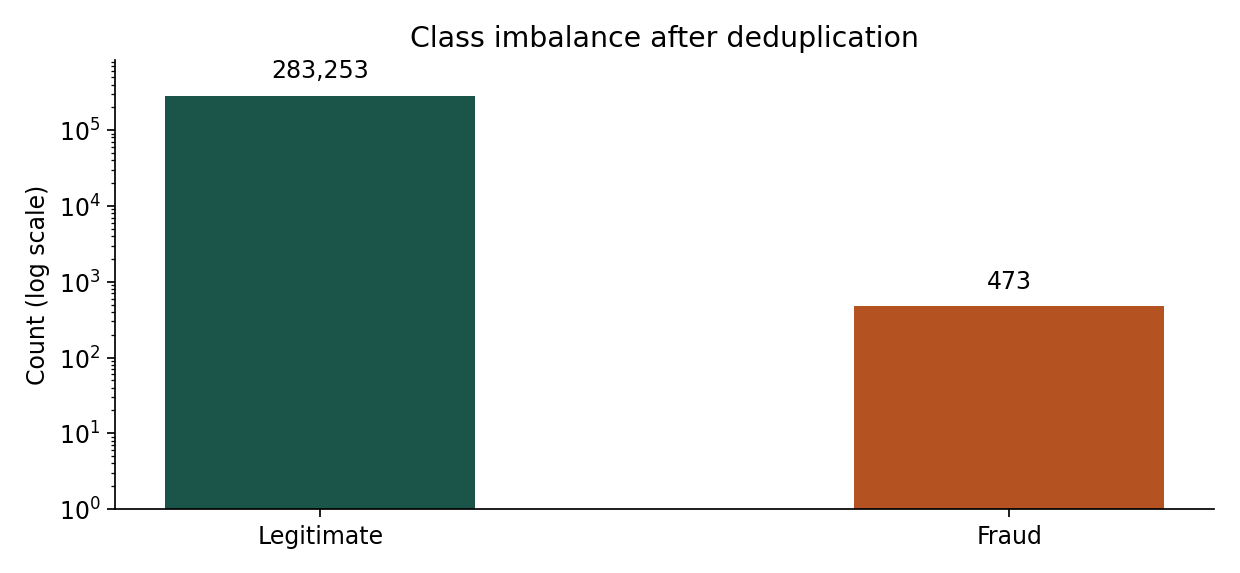

1. Логарифмдік осьте де кластар арасында үлкен айырма көрінеді. Accuracy негізгі өлшем емес.

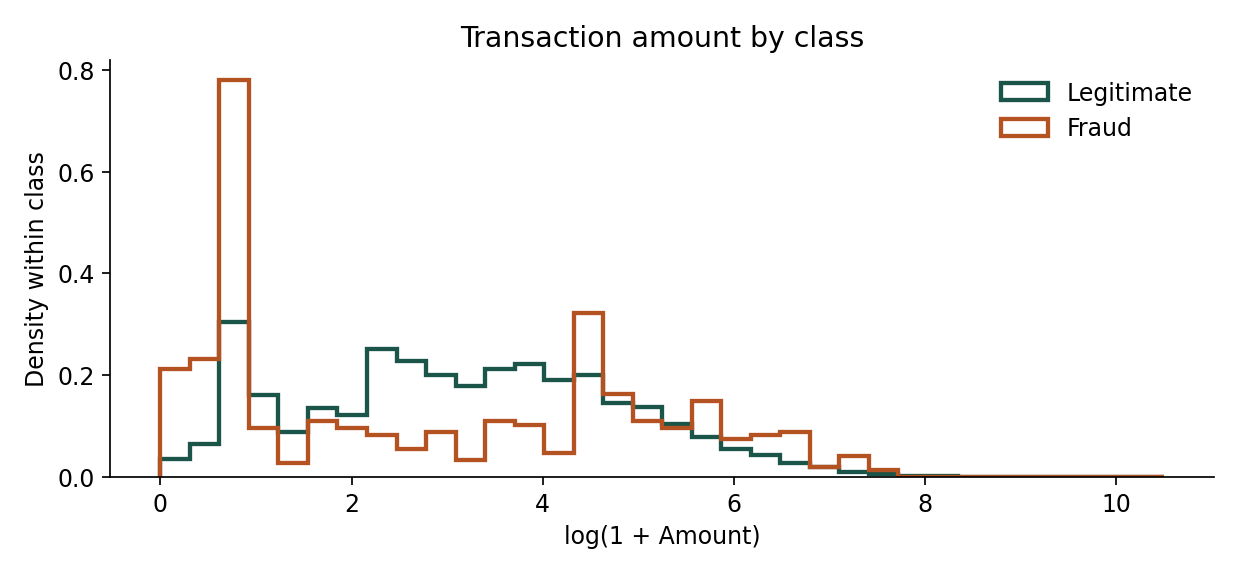

2. Сома үлестірімдері қабаттасады. Сома өздігінен алаяқтықты дәлелдемейді.

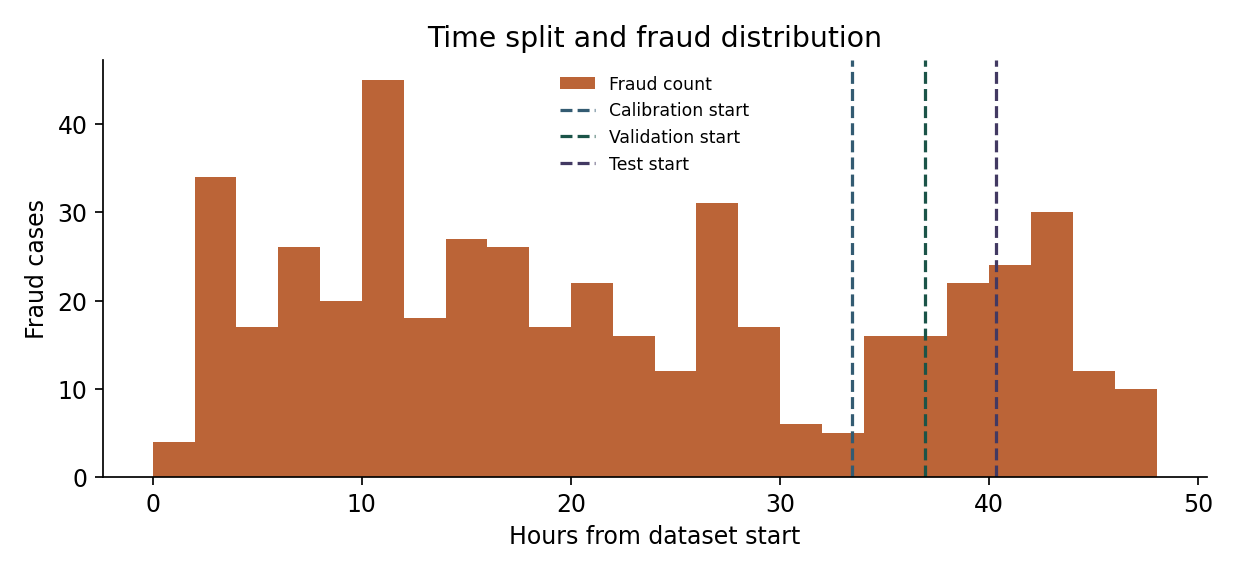

3. Fraud саны уақыт бойынша біркелкі емес. Бөлу хронологиялық тәртіпте жасалады.

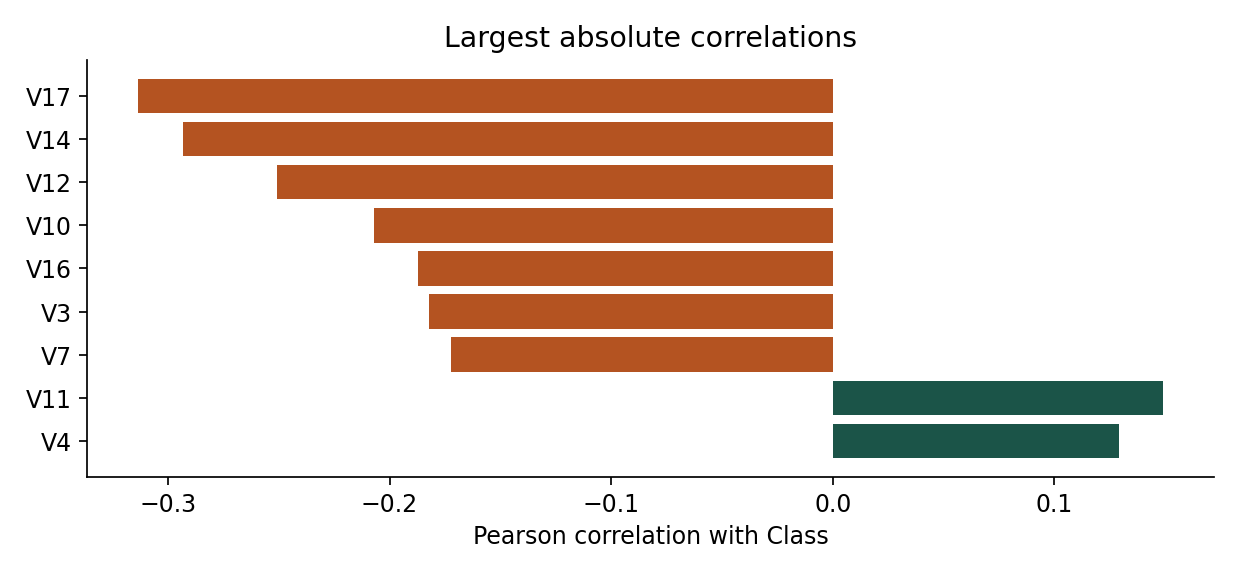

4. V14, V17, V12 сияқты белгілер мақсатпен байланыс көрсетеді. PCA құрамының физикалық мағынасы белгісіз.

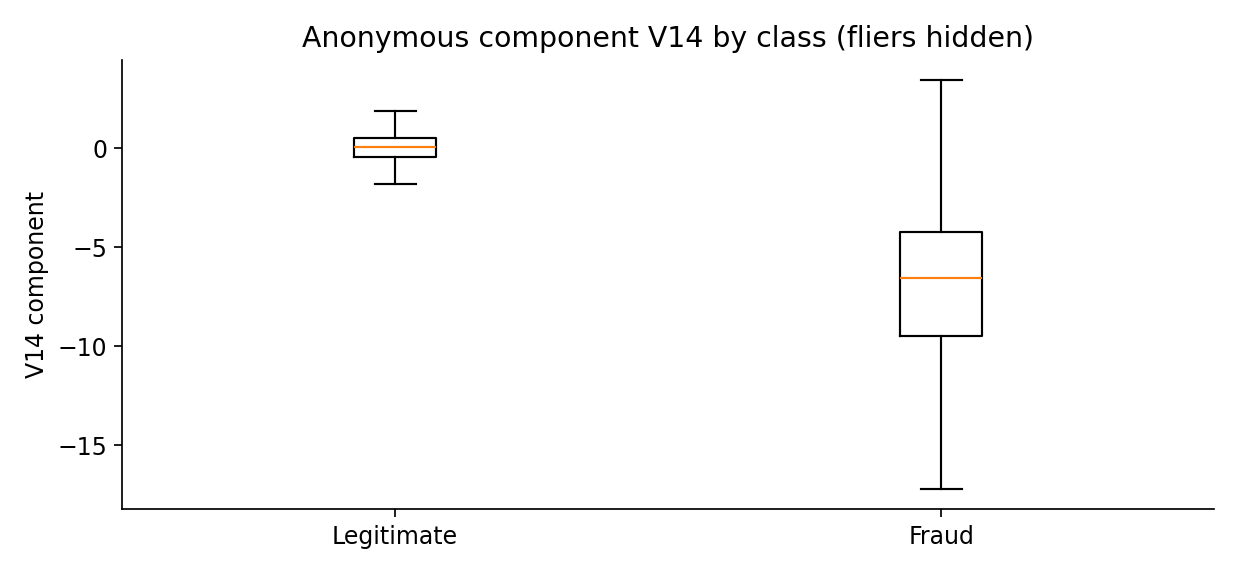

5. V14 таралуының орталық бөлігі екі класта әртүрлі. Қораптық график шеткі мәндерсіз берілген.

## Бөлу және модель іздеу
Медианамен толтыру Pipeline ішінде. Логистикалық модельге StandardScaler қолданылады. Үш модель class_weight арқылы сирек класты ескереді. GridSearchCV train ішінде бес уақыттық фолдты қолданады.

In [2]:
for name, split in m["splits"].items():
    print(name, split)
for candidate in m["cv"]:
    print(candidate["name"], round(candidate["average_precision"], 4),
          [round(x, 4) for x in candidate["fold_ap"]], candidate["parameters"])
print("Таңдалған модель:", m["selected_model"])


train {'rows': 170235, 'fraud': 342, 'min_time': 0, 'max_time': 120392}
calibration {'rows': 28372, 'fraud': 24, 'min_time': 120393, 'max_time': 132905}
validation {'rows': 28373, 'fraud': 33, 'min_time': 132906, 'max_time': 145233}
test {'rows': 56746, 'fraud': 74, 'min_time': 145234, 'max_time': 172792}
Logistic regression 0.7383 [0.7885, 0.7646, 0.6028, 0.6962, 0.8392] {'logisticregression__C': 0.1}
Extra Trees 0.7569 [0.8027, 0.8128, 0.7506, 0.6119, 0.8062] {'extratreesclassifier__max_depth': 17}
Histogram gradient boosting 0.7803 [0.8407, 0.8225, 0.736, 0.7401, 0.7621] {'histgradientboostingclassifier__max_leaf_nodes': 31}
Таңдалған модель: Histogram gradient boosting


## Калибрлеу, шек және соңғы тест
Калибрлеуге жеке уақыт бөлігі берілді. Шек үшін validation-де 25 × FN + FP азайтылды. Тест шешімі тестте қайта бапталмады.

In [3]:
print("Шек:", m["threshold"], "Тексеру аймағының жарты ені:", m["review_width"])
for key in ("validation", "test", "test_at_0_5"):
    row = m[key]
    print(key, {k: round(row[k], 5) for k in
                ("average_precision", "precision", "recall", "tn", "fp", "fn", "tp", "cost", "brier")})


Шек: 0.036652135375509994 Тексеру аймағының жарты ені: 0.0054978203063264985
validation {'average_precision': 0.82851, 'precision': 0.62222, 'recall': 0.84848, 'tn': 28323, 'fp': 17, 'fn': 5, 'tp': 28, 'cost': 142, 'brier': 0.00031}
test {'average_precision': 0.77771, 'precision': 0.65882, 'recall': 0.75676, 'tn': 56643, 'fp': 29, 'fn': 18, 'tp': 56, 'cost': 479, 'brier': 0.00049}
test_at_0_5 {'average_precision': 0.77771, 'precision': 0.87273, 'recall': 0.64865, 'tn': 56665, 'fp': 7, 'fn': 26, 'tp': 48, 'cost': 657, 'brier': 0.00049}


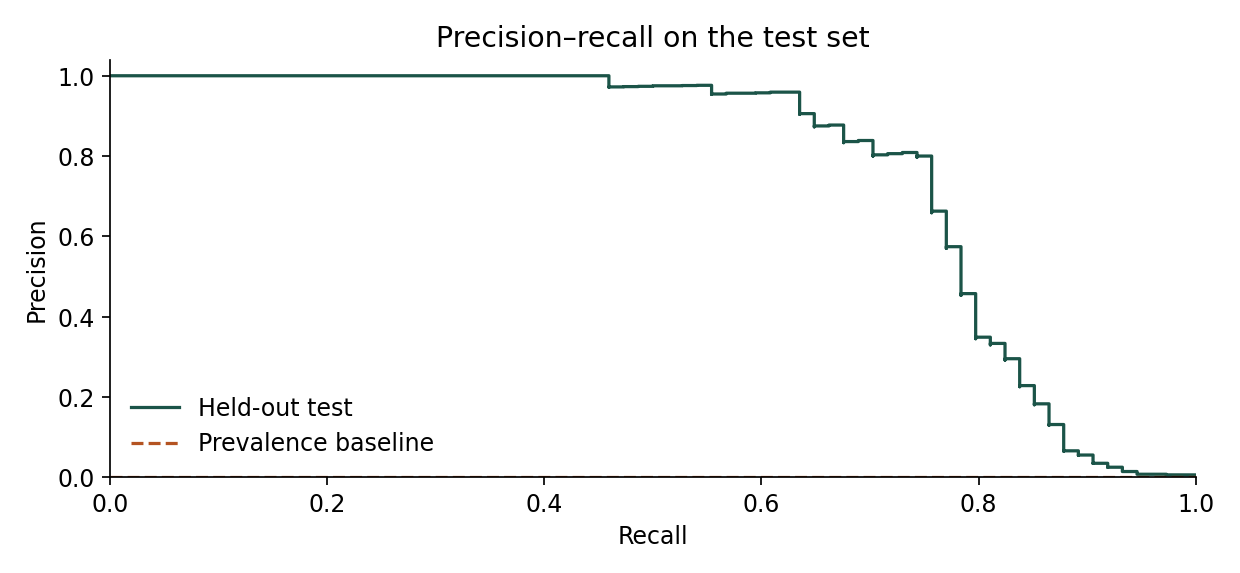

6. PR қисығы. Горизонталь базалық сызық — тест жиынындағы алаяқтық үлесі.

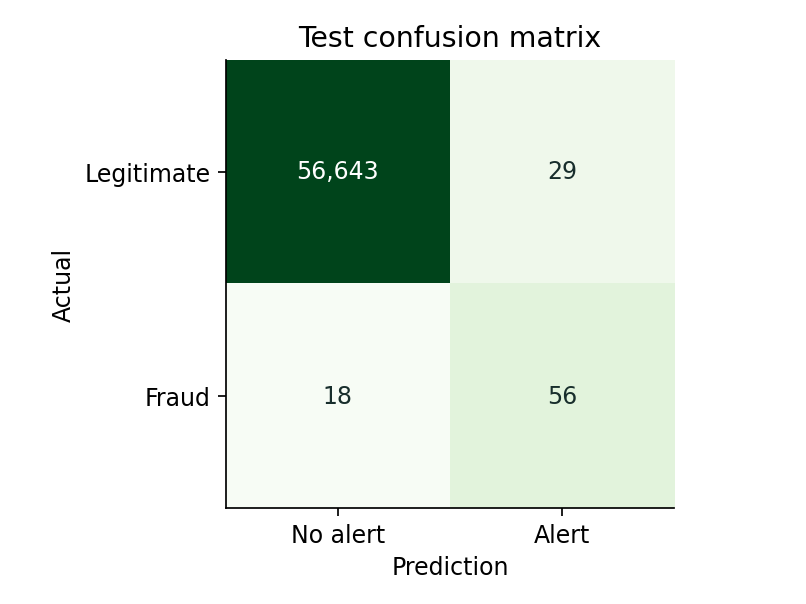

7. Таңдалған шекте 56 дұрыс табылған fraud, 29 жалған дабыл және 18 пропуск.

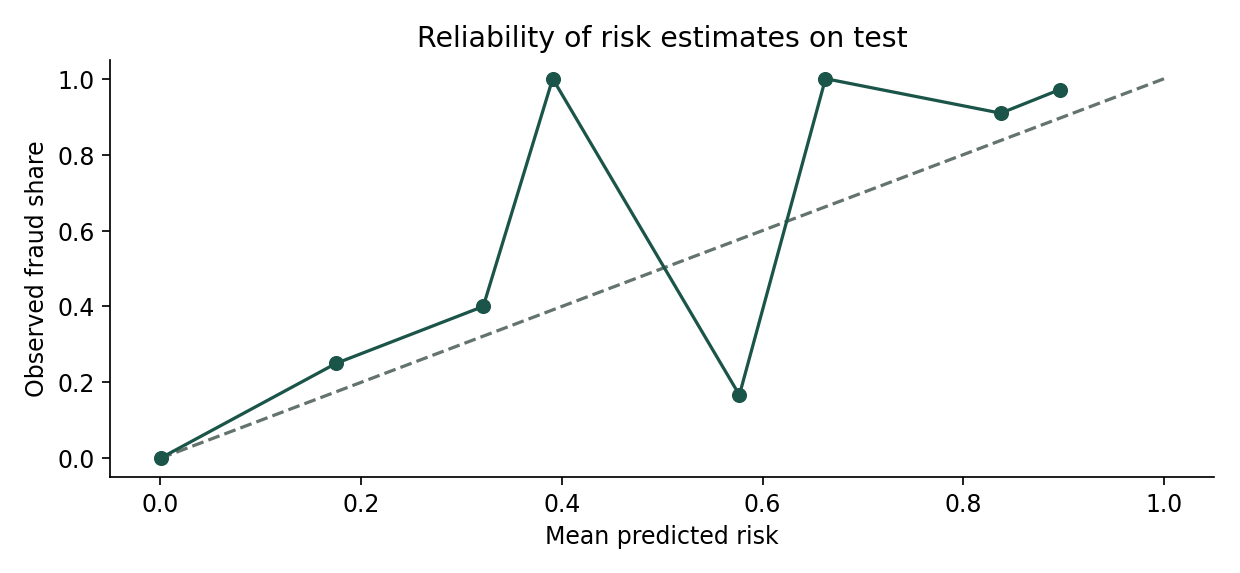

8. Калибрлеу графигін сирек оқиғалар мен аз оң мысал санын ескеріп оқу қажет.

## Белгілердің маңыздылығы және бес қате

In [4]:
for feature in m["importance"][:8]:
    print(feature["feature"], f'{feature["ap_drop"]:.4f}', f'± {feature["std"]:.4f}')
print()
for case in m["errors"]:
    print(case["row"], case["type"], f'{case["score"]:.5%}', case["amount"], case["largest_components"])


V14 0.3752 ± 0.0052
V12 0.1930 ± 0.0179
V4 0.1188 ± 0.0249
V17 0.0677 ± 0.0043
V18 0.0654 ± 0.0018
V7 0.0647 ± 0.0085
V11 0.0581 ± 0.0009
V2 0.0553 ± 0.0025

274382 FN 0.01758% 0.0 {'V5': 9.88056402552862, 'V2': -8.40215367768915}
254344 FN 0.01800% 187.11 {'V14': -1.81638414654661, 'V10': -1.61361833850235}
263080 FN 0.02078% 1.0 {'V3': -3.53075873641584, 'V1': 2.13238602134104}
281674 FN 0.02105% 42.53 {'V3': -2.58344064503516, 'V1': 1.9919760961759}
245347 FN 0.03251% 2.47 {'V4': 2.62028192286183, 'V15': -2.02473460275883}


Модель сеніммен жіберіп алған бес операцияның бәрі FN. Нөлдік немесе шағын сомалар да тәуекелді болуы мүмкін. Компоненттердің нақты бастапқы айнымалылары ашық берілмегендіктен, себеп туралы тұжырым жасауға болмайды. Жиілік және бақылау тізімі ашық деректерде жоқ. Олардың жұмысы API-дағы оқу мысалдарымен бөлек тексеріледі.

## Қайта оқыту
CSV бар кезде келесі ұяшықта `RETRAIN = True` деп өзгертіңіз. `train.py` модельді, көрсеткіштерді және суреттерді жаңартады.

In [5]:
import subprocess
import sys

RETRAIN = False
if RETRAIN:
    subprocess.run([sys.executable, "train.py"], cwd=ROOT, check=True)
